In [1]:
import pickle
import numpy as np
from qkeras.utils import load_qmodel
#from keras.models import load_model
import hls4ml
from sklearn.metrics import accuracy_score
from hls4ml.model.profiling import numerical

2026-09-14 19:42:29.297364: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-14 19:42:29.314721: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-09-14 19:42:29.430132: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-09-14 19:42:29.431062: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-09-14 19:42:29.863505: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:3

In [9]:
def load_pickle_data(path):
    print(f"Lendo {path} ...")
    with open(path, "rb") as f:
        data = pickle.load(f)
    return data["X"], data["y"]

def trace_layers(config):
    config['Model']['TraceOutput'] = True
    for layer in config['LayerName']:
        config['LayerName'][layer]['Trace'] = True


def print_dict(d, indent=0):
    for key, value in d.items():
        print('  ' * indent + str(key), end='')
        if isinstance(value, dict):
            print()
            print_dict(value, indent + 1)
        else:
            print(':' + ' ' * (20 - len(key) - 2 * indent) + str(value))

TRAIN_PICKLE_PATH = "./dataset/sat6_train.pkl"
TEST_PICKLE_PATH = "./dataset/sat6_test.pkl"

X_train_all, y_train_all = load_pickle_data(TRAIN_PICKLE_PATH)
X_test, y_test = load_pickle_data(TEST_PICKLE_PATH)

X_train_all = X_train_all.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

val_idx = int(0.75 * len(X_train_all))
X_train, y_train = X_train_all[:val_idx], y_train_all[:val_idx]
X_val, y_val = X_train_all[val_idx:], y_train_all[val_idx:]

n_classes = 6
input_shape = X_train.shape[1:]
train_size = len(X_train)

BASE_DIR = 'qkeras_model' #'base_model_t1'
MODEL_NAME = 'model' #'t1_model'
FINAL_PATH = f"models/{BASE_DIR}/{MODEL_NAME}.h5"

qmodel = load_qmodel(FINAL_PATH)

Lendo ./dataset/sat6_train.pkl ...
Lendo ./dataset/sat6_test.pkl ...


In [10]:
OUTPUT_DIR = f"./prj_{BASE_DIR}"
FPGA_PART = "xc7z020clg400-1"
CLOCK_PERIOD_NS = 10
IO_TYPE = "io_stream"
BACKEND = "Vitis"

hls_config = hls4ml.utils.config_from_keras_model(
    qmodel,
    granularity="name",
    backend='Vitis',
)
hls_config['LayerName']['output_dense']['Precision']['result'] = 'fixed<16,6,RND,SAT>'

trace_layers(hls_config)
print_dict(hls_config)

hls_model = hls4ml.converters.convert_from_keras_model(
    qmodel,
    hls_config=hls_config,
    output_dir=OUTPUT_DIR,
    part=FPGA_PART,
    clock_period=CLOCK_PERIOD_NS,
    io_type=IO_TYPE,
    backend=BACKEND,
)
hls_model.compile()

Model
  Precision
    default:         fixed<16,6>
  ReuseFactor:       1
  Strategy:          Latency
  BramFactor:        1000000000
  TraceOutput:       True
LayerName
  input_2
    Trace:           True
    Precision
      result:        auto
  conv_0
    Trace:           True
    Precision
      result:        auto
      weight:        fixed<8,1,TRN,WRAP,0>
      bias:          auto
      accum:         auto
    ReuseFactor:     1
    ParallelizationFactor:1
    ConvImplementation:LineBuffer
  conv_0_linear
    Trace:           True
    Precision
      result:        auto
      table:         fixed<18,8,TRN,WRAP,0>
    ReuseFactor:     1
    TableSize:       1024
  conv_act_0
    Trace:           True
    Precision
      result:        ufixed<8,0,RND_CONV,SAT,0>
      table:         fixed<18,8,TRN,WRAP,0>
    ReuseFactor:     1
    TableSize:       1024
  conv_1
    Trace:           True
    Precision
      result:        auto
      weight:        fixed<8,1,TRN,WRAP,0>
      bias:

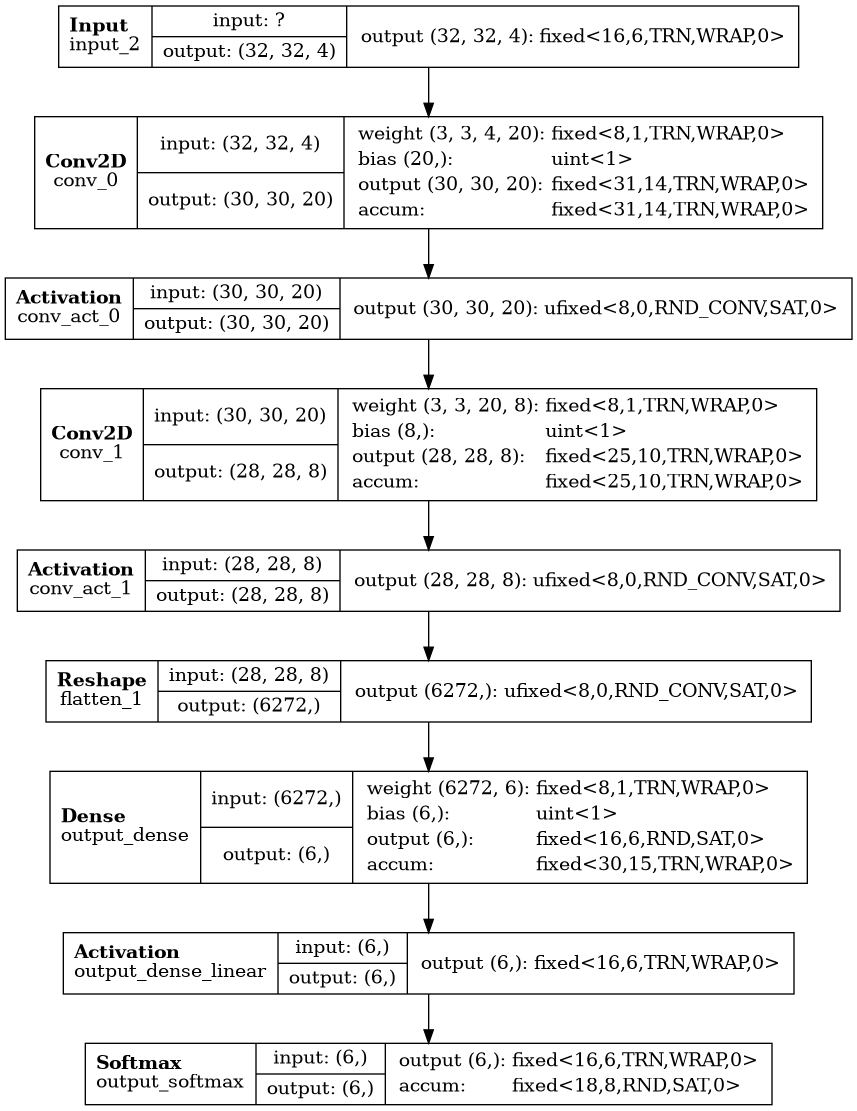

In [11]:
hls4ml.utils.plot_model(hls_model, show_shapes=True, show_precision=True, to_file=None)

Profiling weights (before optimization)
Weights for conv_0 are only zeros, ignoring.
Weights for conv_1 are only zeros, ignoring.
Weights for output_dense are only zeros, ignoring.
[{'med': 0.1953125, 'q1': 0.09375, 'q3': 0.3515625, 'whislo': 0.0078125, 'whishi': 0.9140625, 'layer': 'conv_0', 'weight': 'conv_0/w'}, {'med': 0.171875, 'q1': 0.0859375, 'q3': 0.3046875, 'whislo': 0.0078125, 'whishi': 1.0, 'layer': 'conv_1', 'weight': 'conv_1/w'}, {'med': 0.1015625, 'q1': 0.046875, 'q3': 0.1953125, 'whislo': 0.0078125, 'whishi': 1.0, 'layer': 'output_dense', 'weight': 'output_dense/w'}]
Profiling weights (final / after optimization)
Weights for conv_0 are only zeros, ignoring.
Weights for conv_1 are only zeros, ignoring.
Weights for output_dense are only zeros, ignoring.
Profiling activations (before optimization)
63/63 [==============================] - 0s 3ms/step
   conv_0
   conv_act_0
   conv_1
   conv_act_1
   flatten_1
   output_dense
   output_softmax
Profiling activations (final / 

(<Figure size 640x480 with 1 Axes>,
 <Figure size 640x480 with 1 Axes>,
 <Figure size 640x480 with 1 Axes>,
 <Figure size 640x480 with 1 Axes>)

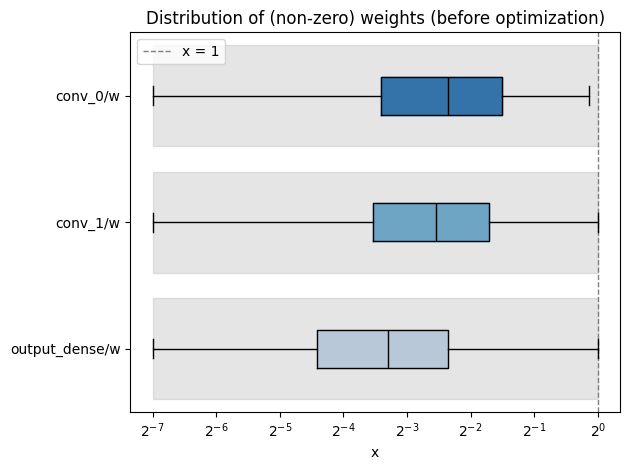

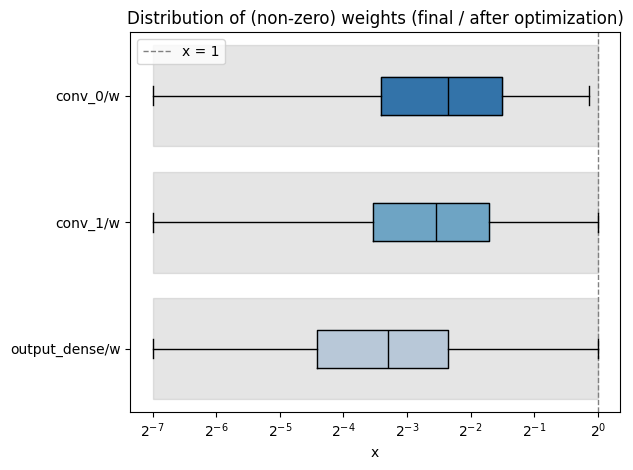

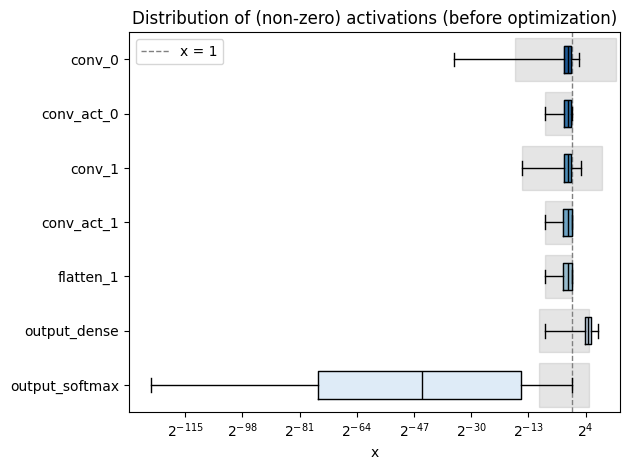

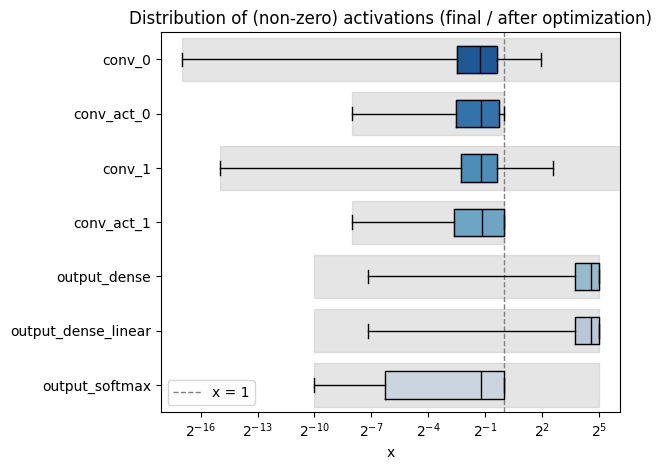

In [12]:
numerical(model=qmodel, hls_model=hls_model, X=X_test[:2000], plot='boxplot')

In [13]:
X_test_reduced = np.ascontiguousarray(X_test[:3000])
Y_test_reduced = np.array(y_test[:3000])

y_qkeras = qmodel.predict(X_test_reduced)
y_pred_hls = hls_model.predict(X_test_reduced)

print('Accuracy quantized: {}'.format(accuracy_score(np.argmax(Y_test_reduced, axis=1), np.argmax(y_qkeras, axis=1))))
print('Accuracy hls4ml: {}'.format(accuracy_score(np.argmax(Y_test_reduced, axis=1), np.argmax(y_pred_hls, axis=1))))


94/94 [==============================] - 0s 2ms/step


Accuracy quantized: 0.9926666666666667
Accuracy hls4ml: 0.9916666666666667


In [ ]:
hls_model.build(csim=False, synth=True, vsynth=True)


****** vitis-run v2024.2 (64-bit)
  **** SW Build 5239630 on 2024-11-10-11:19:46
  **** Start of session at: Mon Sep 14 21:25:19 2026
    ** Copyright 1986-2022 Xilinx, Inc. All Rights Reserved.
    ** Copyright 2022-2024 Advanced Micro Devices, Inc. All Rights Reserved.

  **** HLS Build v2024.2 5238294
Sourcing Tcl script '/home/fauri/Documentos/hls4ml/sat_6_tensorflow/prj_qkeras_model/build_prj.tcl'
INFO: [HLS 200-1510] Running: open_project myproject_prj 
INFO: [HLS 200-10] Creating and opening project '/home/fauri/Documentos/hls4ml/sat_6_tensorflow/prj_qkeras_model/myproject_prj'.
INFO: [HLS 200-1510] Running: set_top myproject 
INFO: [HLS 200-1510] Running: add_files firmware/myproject.cpp -cflags -std=c++0x 
INFO: [HLS 200-10] Adding design file 'firmware/myproject.cpp' to the project
INFO: [HLS 200-1510] Running: add_files -tb myproject_test.cpp -cflags -std=c++0x 
INFO: [HLS 200-10] Adding test bench file 'myproject_test.cpp' to the project
INFO: [HLS 200-1510] Running: add_f